# Croping

In [ ]:
# %% [markdown]
# # Crop processed SWOT NetCDF files to 700 x 60

# %%
from pathlib import Path

import xarray as xr

In [ ]:
# %% [markdown]
# # Paths and settings

# %%
INPUT_DIR = Path("../../data/raw/SWOT_L3_BOB_Dataset/processed_data")

OUTPUT_DIR = Path("../../data/interim/SWOT_L3_BOB_Dataset/processed_data_clipped")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_HEIGHT = 700
TARGET_WIDTH = 60

REFERENCE_VARS = [
    "rolling_mean_highpass",
    "ssha_unfiltered",
    "iw_bbox_mask",
    "block_mask",
]

print("Input directory: ", INPUT_DIR)
print("Output directory:", OUTPUT_DIR)

In [ ]:
# %% [markdown]
# # Helper functions

# %%
def find_spatial_dims(ds, reference_vars=REFERENCE_VARS):
    """
    Find the two spatial dimensions to crop.

    Uses the first available reference variable.
    Ignores:
      - file dimension
      - singleton dimensions
    """
    for var_name in reference_vars:
        if var_name not in ds:
            continue

        da = ds[var_name]

        candidate_dims = []

        for dim in da.dims:
            if dim == "file":
                continue

            if da.sizes[dim] <= 1:
                continue

            candidate_dims.append(dim)

        if len(candidate_dims) == 2:
            y_dim, x_dim = candidate_dims
            return y_dim, x_dim, var_name

    raise ValueError(
        "Could not find two spatial dimensions from reference variables: "
        f"{reference_vars}"
    )


def centered_crop_slices(height, width, target_height, target_width):
    """
    Compute centered crop slices.

    If the number of pixels to remove is odd, the extra pixel is removed
    from the bottom or right side.
    """
    if height < target_height:
        raise ValueError(
            f"Cannot crop height {height} to target height {target_height}"
        )

    if width < target_width:
        raise ValueError(
            f"Cannot crop width {width} to target width {target_width}"
        )

    crop_y = height - target_height
    crop_x = width - target_width

    top = crop_y // 2
    left = crop_x // 2

    bottom = top + target_height
    right = left + target_width

    return (
        slice(top, bottom),
        slice(left, right),
        top,
        height - bottom,
        left,
        width - right,
    )


def crop_dataset(ds, target_height=TARGET_HEIGHT, target_width=TARGET_WIDTH):
    """
    Center-crop the dataset using xarray isel.

    This crops every variable that uses the selected spatial dimensions,
    so masks and data stay aligned.
    """
    y_dim, x_dim, ref_var = find_spatial_dims(ds)

    height = ds.sizes[y_dim]
    width = ds.sizes[x_dim]

    y_slice, x_slice, top, bottom_removed, left, right_removed = centered_crop_slices(
        height=height,
        width=width,
        target_height=target_height,
        target_width=target_width,
    )

    ds_cropped = ds.isel({
        y_dim: y_slice,
        x_dim: x_slice,
    })

    ds_cropped.attrs.update(ds.attrs)

    ds_cropped.attrs["crop_note"] = (
        f"Centered crop to height={target_height}, width={target_width}. "
        f"Cropped y dimension {y_dim}: removed top={top}, bottom={bottom_removed}. "
        f"Cropped x dimension {x_dim}: removed left={left}, right={right_removed}. "
        f"Spatial dims detected from variable {ref_var}."
    )

    info = {
        "y_dim": y_dim,
        "x_dim": x_dim,
        "ref_var": ref_var,
        "original_height": height,
        "original_width": width,
        "target_height": target_height,
        "target_width": target_width,
        "removed_top": top,
        "removed_bottom": bottom_removed,
        "removed_left": left,
        "removed_right": right_removed,
    }

    return ds_cropped, info

In [ ]:
# %% [markdown]
# # Check files before cropping

# %%
nc_files = sorted(INPUT_DIR.glob("*.nc"))

print(f"Found {len(nc_files)} NetCDF files")

if len(nc_files) > 0:
    first_file = nc_files[0]
    print("First file:", first_file.name)

    with xr.open_dataset(first_file) as ds:
        print("\nDimensions:")
        print(dict(ds.sizes))

        print("\nVariables:")
        for name, var in ds.variables.items():
            print(f"{name}: dims={var.dims}, shape={var.shape}")

In [ ]:
# %% [markdown]
# # Crop all NetCDF files

# %%
processed = 0
failed = 0
failures = []

for nc_file in nc_files:
    print(f"\nProcessing: {nc_file.name}")

    try:
        with xr.open_dataset(nc_file) as ds:
            ds_loaded = ds.load()

        ds_cropped, info = crop_dataset(ds_loaded)

        out_path = OUTPUT_DIR / nc_file.name
        tmp_path = out_path.with_suffix(out_path.suffix + ".tmp")

        if tmp_path.exists():
            tmp_path.unlink()

        ds_cropped.to_netcdf(tmp_path)

        if out_path.exists():
            out_path.unlink()

        tmp_path.replace(out_path)

        ds_loaded.close()
        ds_cropped.close()

        processed += 1

        print(f"Saved: {out_path}")
        print(
            f"Original shape: ({info['original_height']}, {info['original_width']}) "
            f"-> cropped shape: ({info['target_height']}, {info['target_width']})"
        )
        print(
            f"Removed top={info['removed_top']}, bottom={info['removed_bottom']}, "
            f"left={info['removed_left']}, right={info['removed_right']}"
        )

    except Exception as e:
        failed += 1
        failures.append(f"{nc_file.name}: {type(e).__name__}: {e}")
        print(f"FAILED: {type(e).__name__}: {e}")

print("\nDone.")
print(f"Processed: {processed}")
print(f"Failed:    {failed}")

if failures:
    print("\nFailures:")
    for failure in failures:
        print(failure)

In [ ]:
# %% [markdown]
# # Verify cropped outputs

# %%
cropped_files = sorted(OUTPUT_DIR.glob("*.nc"))

print(f"Found {len(cropped_files)} cropped files")

if len(cropped_files) > 0:
    verify_file = cropped_files[0]
    print("Verify file:", verify_file.name)

    with xr.open_dataset(verify_file) as ds:
        print("\nDimensions:")
        print(dict(ds.sizes))

        print("\nVariables:")
        for name, var in ds.variables.items():
            print(f"{name}: dims={var.dims}, shape={var.shape}")

# misc

In [ ]:
from pathlib import Path
import pandas as pd

# Path to the CSV containing the image_name column
csv_path = Path("../../data/splits/split_assignments.csv")


# Folder containing the labeled NetCDF files
target_dir = Path("../../data/processed/block_labeled_data")
# target_dir = Path("../../data/interim/SWOT_L3_BOB_Dataset/processed_data_clipped")


# Set to False after verifying the printed results
dry_run = True


# Read the CSV and remove the .jpg extension from each image name
df = pd.read_csv(csv_path)

valid_prefixes = {
    Path(image_name).stem
    for image_name in df["image_name"].dropna()
}

kept_files = []
removed_files = []

for file_path in target_dir.iterdir():
    # Skip directories
    if not file_path.is_file():
        continue

    # Keep the file when its name begins with one of the CSV image stems
    should_keep = any(
        file_path.name.startswith(prefix)
        for prefix in valid_prefixes
    )

    if should_keep:
        kept_files.append(file_path.name)
    else:
        removed_files.append(file_path.name)

        if not dry_run:
            file_path.unlink()


print(f"Valid image prefixes: {len(valid_prefixes)}")
print(f"Files kept: {len(kept_files)}")
print(f"Files {'that would be removed' if dry_run else 'removed'}: {len(removed_files)}")

for filename in removed_files:
    print(f"{'WOULD REMOVE' if dry_run else 'REMOVED'}: {filename}")

# Labler Logic

In [1]:
# Imports & globals

# %%
%matplotlib widget

from pathlib import Path

import numpy as np
import xarray as xr
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.patches as patches


# ============================================================
# Paths
# ============================================================

# These are the NetCDFs created from the YOLO bbox processing step.
DATA_DIR = Path("../../data/interim/SWOT_L3_BOB_Dataset/processed_data_clipped")

# Saves edited/block-label NetCDFs here.
OUTPUT_DIR = Path("../../data/processed/block_labeled_data")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# Variables
# ============================================================

# Variable to display while labeling.
VAR_NAME = "rolling_mean_highpass"

# Existing pixel-level YOLO bbox mask from the processed NetCDFs.
SOURCE_MASK_VAR_NAME = "iw_bbox_mask"

# New block-level mask that this labeler saves.
OUTPUT_MASK_VAR_NAME = "block_mask"


# ============================================================
# Block settings
# ============================================================

BLOCK_H = 20
BLOCK_W = 20

# A block is preselected if more than this fraction of its pixels
# have SOURCE_MASK_VALUE in SOURCE_MASK_VAR_NAME.
MAJORITY_THRESHOLD = 0.5
SOURCE_MASK_VALUE = 1


# ============================================================
# Display settings
# ============================================================

# Use "none" for no transpose/no flip.
# You can change to "make_vertical" later if you want the long dimension vertical.
ORIENT_MODE = "none"

CMAP = "magma"
VMIN_PERCENTILE = 2.5
VMAX_PERCENTILE = 97.5
INTERPOLATION = "none"

FIG_W_IN = 6
FIG_H_IN = 10
FIG_DPI = 140

GRID_COLOR = "white"
GRID_LINEWIDTH = 0.25
RECT_EDGE_LW = 0.4

SELECT_FACE = "yellow"
SELECT_ALPHA = 0.65

In [2]:
# Inspect first processed NetCDF

# %%
def show_first_nc_dims(input_dir=DATA_DIR):
    f = next(iter(sorted(Path(input_dir).glob("*.nc"))), None)

    if f is None:
        print(f"No NetCDF files found in {input_dir}")
        return

    with xr.open_dataset(f) as ds:
        print(f"File: {f.name}")

        print("\nDimensions:")
        print(dict(ds.sizes))

        print("\nVariables:")
        for name, var in ds.variables.items():
            print(f"{name}: dims={var.dims}, shape={var.shape}")


show_first_nc_dims()

File: SWOT_L3_LR_SSH_Expert_001_161_20230726T224518_20230726T233644_v3.0.nc

Dimensions:
{'num_lines': 700, 'num_pixels': 60, 'num_nadir': 1384}

Variables:
time: dims=('num_lines',), shape=(700,)
calibration: dims=('num_lines', 'num_pixels'), shape=(700, 60)
cross_track_distance: dims=('num_pixels',), shape=(60,)
dac: dims=('num_lines', 'num_pixels'), shape=(700, 60)
internal_tide: dims=('num_lines', 'num_pixels'), shape=(700, 60)
mdt: dims=('num_lines', 'num_pixels'), shape=(700, 60)
mss: dims=('num_lines', 'num_pixels'), shape=(700, 60)
ocean_tide: dims=('num_lines', 'num_pixels'), shape=(700, 60)
quality_flag: dims=('num_lines', 'num_pixels'), shape=(700, 60)
sigma0: dims=('num_lines', 'num_pixels'), shape=(700, 60)
ssha_filtered: dims=('num_lines', 'num_pixels'), shape=(700, 60)
ssha_unedited: dims=('num_lines', 'num_pixels'), shape=(700, 60)
ssha_unfiltered: dims=('num_lines', 'num_pixels'), shape=(700, 60)
ugos_filtered: dims=('num_lines', 'num_pixels'), shape=(700, 60)
ugosa_fi

In [3]:
# Orientation helpers

# %%
def apply_orientation(arr: np.ndarray, mode: str) -> np.ndarray:
    """
    Display orientation only.

    mode="none":
        no transpose, no flip

    mode="make_vertical":
        transpose only if width > height
    """
    if mode == "none":
        return arr

    if mode == "make_vertical":
        if arr.shape[1] > arr.shape[0]:
            return arr.T
        return arr

    raise ValueError(f"Unknown ORIENT_MODE: {mode}")


def invert_orientation(mask_plot: np.ndarray, native_shape: tuple, mode: str) -> np.ndarray:
    """
    Convert displayed mask back to native NetCDF grid orientation.
    """
    if mode == "none":
        if mask_plot.shape != native_shape:
            raise ValueError(
                f"Mask shape {mask_plot.shape} does not match native shape {native_shape}"
            )
        return mask_plot

    if mode == "make_vertical":
        if mask_plot.shape == native_shape:
            return mask_plot

        if mask_plot.T.shape == native_shape:
            return mask_plot.T

        raise ValueError(
            f"Could not invert mask shape {mask_plot.shape} back to native shape {native_shape}"
        )

    raise ValueError(f"Unknown ORIENT_MODE: {mode}")

In [4]:
# Utility functions

# %%
def list_nc_files(data_dir: Path, output_dir: Path = None):
    """
    List processed .nc files that still need block labeling.

    Excludes:
    1. Files that already end with _labeled.nc
    2. Files that already have a matching *_labeled.nc in output_dir
    """
    files = []

    for p in sorted(data_dir.glob("*.nc")):
        if not p.is_file():
            continue

        if p.name.endswith("_labeled.nc"):
            continue

        if output_dir is not None:
            labeled_path = output_dir / f"{p.stem}_labeled.nc"
            if labeled_path.exists():
                continue

        files.append(p)

    return files


def list_labeled_nc_files(output_dir: Path):
    return sorted([p for p in output_dir.glob("*_labeled.nc") if p.is_file()])


def select_2d_da(da: xr.DataArray):
    """
    Select the same 2D slice from a possibly higher-dimensional DataArray.

    If there is a 'file' dimension, use file=0.
    Also squeezes singleton dimensions.

    Returns:
        da2d, selectors
    """
    selectors = {}

    if "file" in da.dims:
        selectors["file"] = 0

    for dim in da.dims:
        if dim in selectors:
            continue

        if da.sizes[dim] == 1:
            selectors[dim] = 0

    da2d = da.isel(selectors).squeeze(drop=True)

    if da2d.ndim != 2:
        raise ValueError(
            f"Expected 2D variable after selecting/squeezing, got "
            f"dims={da2d.dims}, shape={da2d.shape}"
        )

    return da2d, selectors


def get_2d_da(ds: xr.Dataset, var_name: str):
    if var_name not in ds:
        raise KeyError(f"Variable {var_name!r} not found in dataset")

    return select_2d_da(ds[var_name])


def grid_shape(H: int, W: int, bh: int, bw: int):
    """
    Number of block rows/cols.

    Uses ceil so arrays do NOT need to be perfectly divisible by 20.
    Edge blocks are allowed to be smaller.
    """
    rows = int(np.ceil(H / bh))
    cols = int(np.ceil(W / bw))
    return rows, cols


def block_bounds(r: int, c: int, H: int, W: int, bh: int, bw: int):
    """
    Pixel bounds for one block, clipping edge blocks to array size.
    """
    y0 = r * bh
    y1 = min((r + 1) * bh, H)

    x0 = c * bw
    x1 = min((c + 1) * bw, W)

    return y0, y1, x0, x1


def blocks_to_pixel_mask(selected_blocks: np.ndarray, H: int, W: int, bh: int, bw: int):
    """
    Convert block-level selections to a full pixel-level mask.

    Every selected block becomes fully filled with 1s.
    """
    rows, cols = selected_blocks.shape
    pixel_mask = np.zeros((H, W), dtype=np.uint8)

    for r in range(rows):
        for c in range(cols):
            if selected_blocks[r, c]:
                y0, y1, x0, x1 = block_bounds(r, c, H, W, bh, bw)
                pixel_mask[y0:y1, x0:x1] = 1

    return pixel_mask


def pixel_mask_to_blocks_majority(
    pixel_mask: np.ndarray,
    bh: int,
    bw: int,
    mask_value: int = 1,
    threshold: float = 0.5,
):
    """
    Convert a pixel-level mask into block-level selections.

    A block is selected if more than `threshold` fraction of pixels
    have value == mask_value.

    For your case:
        source mask = iw_bbox_mask
        selected if more than 50% of the 20x20 patch is inside bbox
    """
    H, W = pixel_mask.shape
    rows, cols = grid_shape(H, W, bh, bw)

    selected = np.zeros((rows, cols), dtype=bool)

    for r in range(rows):
        for c in range(cols):
            y0, y1, x0, x1 = block_bounds(r, c, H, W, bh, bw)
            patch = pixel_mask[y0:y1, x0:x1]

            if patch.size == 0:
                continue

            frac = np.mean(patch == mask_value)

            if frac > threshold:
                selected[r, c] = True

    return selected


def robust_limits(arr, lower=2.5, upper=97.5):
    arr = np.asarray(arr)

    if not np.isfinite(arr).any():
        return None, None

    vmin, vmax = np.nanpercentile(arr, [lower, upper])

    if not np.isfinite(vmin) or not np.isfinite(vmax) or vmin == vmax:
        return None, None

    return float(vmin), float(vmax)


def make_full_sized_mask_da(
    base_da: xr.DataArray,
    mask_2d: np.ndarray,
    spatial_dims: tuple,
    selectors: dict,
    name: str,
):
    """
    Create a full-size DataArray matching base_da dims.

    The 2D mask is inserted into the selected slice, usually file=0.
    Other slices are filled with 0.
    """
    full_shape = tuple(base_da.sizes[dim] for dim in base_da.dims)
    full = np.zeros(full_shape, dtype=np.uint8)

    indexer = []

    for dim in base_da.dims:
        if dim in spatial_dims:
            indexer.append(slice(None))
        elif dim in selectors:
            indexer.append(selectors[dim])
        else:
            raise ValueError(
                f"Dimension {dim!r} is neither spatial nor selected. "
                f"base_da dims={base_da.dims}, spatial_dims={spatial_dims}, "
                f"selectors={selectors}"
            )

    full[tuple(indexer)] = mask_2d.astype(np.uint8)

    coords = {
        dim: base_da.coords[dim]
        for dim in base_da.dims
        if dim in base_da.coords
    }

    return xr.DataArray(
        full,
        dims=base_da.dims,
        coords=coords,
        name=name,
        attrs={
            "description": "Block-level mask. 1=selected block, 0=not selected.",
            "block_h": int(BLOCK_H),
            "block_w": int(BLOCK_W),
            "source": "interactive_block_labeler_ipynb",
            "display_variable": VAR_NAME,
            "source_mask_variable": SOURCE_MASK_VAR_NAME,
            "source_mask_value": int(SOURCE_MASK_VALUE),
            "majority_threshold": float(MAJORITY_THRESHOLD),
            "rule": (
                f"Initial block selected when more than {MAJORITY_THRESHOLD:.2f} "
                f"of pixels in the {BLOCK_H}x{BLOCK_W} patch equal {SOURCE_MASK_VALUE} "
                f"in {SOURCE_MASK_VAR_NAME}."
            ),
            "orient_mode": ORIENT_MODE,
        },
    )

In [5]:
# Interactive labeler
# %%
class BlockLabelerFromProcessedNC:
    def __init__(
        self,
        data_dir: Path,
        output_dir: Path,
        var_name: str,
        source_mask_var_name: str,
        output_mask_var_name: str,
        orient_mode: str = "none",
        block_h: int = 20,
        block_w: int = 20,
        majority_threshold: float = 0.5,
        source_mask_value: int = 1,
        fig_w_in: float = 6,
        fig_h_in: float = 10,
        fig_dpi: int = 140,
    ):
        self.data_dir = data_dir
        self.output_dir = output_dir
        self.var_name = var_name
        self.source_mask_var_name = source_mask_var_name
        self.output_mask_var_name = output_mask_var_name
        self.orient_mode = orient_mode
        self.block_h = block_h
        self.block_w = block_w
        self.majority_threshold = majority_threshold
        self.source_mask_value = source_mask_value

        self.fig_w_in = fig_w_in
        self.fig_h_in = fig_h_in
        self.fig_dpi = fig_dpi

        self.mode = "raw"
        self.raw_files = list_nc_files(self.data_dir, self.output_dir)
        self.labeled_files = list_labeled_nc_files(self.output_dir)
        self.files = self.raw_files
        self.idx = 0

        # filename -> block selections
        self.selections = {}

        self.rows = None
        self.cols = None
        self.H = None
        self.W = None
        self.current_init_message = ""

        plt.close("all")

        self.fig, self.ax = plt.subplots(
            figsize=(self.fig_w_in, self.fig_h_in),
            dpi=self.fig_dpi,
        )

        self.ax.set_aspect("equal")
        self.cid = None
        self.rects = []
        self.image_plot = None

        # Display-only toggle.
        # This does NOT change selected labels or saved masks.
        self.show_mask_highlight = True

        # Controls
        self.prev_btn = widgets.Button(description="Previous")
        self.next_btn = widgets.Button(description="Next")
        self.save_btn = widgets.Button(description="Save", button_style="success")

        self.mask_toggle = widgets.ToggleButton(
            value=True,
            description="Mask highlight: On",
            button_style="info",
            tooltip="Show or hide selected mask/block highlights",
            icon="eye",
        )

        self.zoom = widgets.FloatSlider(
            description="Zoom",
            min=1.0,
            max=8.0,
            step=0.1,
            value=1.0,
            continuous_update=True,
        )

        self.status = widgets.HTML(value="<b>Status:</b> Ready")

        self.prev_btn.on_click(self.on_prev)
        self.next_btn.on_click(self.on_next)
        self.save_btn.on_click(self.on_save)
        self.mask_toggle.observe(self.on_mask_toggle, names="value")
        self.zoom.observe(self.on_zoom, names="value")

        # Tabs
        self.raw_tab = widgets.VBox([
            widgets.HTML(
                "<b>Label processed NCs</b><br>"
                f"Loads files from <code>{self.data_dir}</code> and initializes blocks from "
                f"<code>{self.source_mask_var_name}</code>."
            )
        ])

        self.labeled_tab = widgets.VBox([
            widgets.HTML(
                "<b>Edit saved block labels</b><br>"
                f"Loads <code>*_labeled.nc</code> files from <code>{self.output_dir}</code>."
            )
        ])

        self.tabs = widgets.Tab(children=[self.raw_tab, self.labeled_tab])
        self.tabs.set_title(0, "Label processed NCs")
        self.tabs.set_title(1, "Edit block labels")
        self.tabs.observe(self.on_tab_change, names="selected_index")

        controls = widgets.HBox([
            self.prev_btn,
            self.next_btn,
            self.save_btn,
            self.mask_toggle,
            self.zoom,
        ])

        self.load_file_list_for_mode()

        if len(self.files) > 0:
            self.load_and_draw(self.files[self.idx])
        else:
            self.ax.clear()
            self.status.value = (
                f"<b>Status:</b> No files found for mode '{self.mode}'."
            )

        display(self.tabs)
        display(controls)
        display(self.status)

        # Do not display self.fig.canvas here.
        # In %matplotlib widget mode, Jupyter already shows the figure.

    # --------------------------------------------------------
    # File mode handling
    # --------------------------------------------------------
    def load_file_list_for_mode(self):
        if self.mode == "raw":
            self.raw_files = list_nc_files(self.data_dir, self.output_dir)
            self.files = self.raw_files

        elif self.mode == "labeled":
            self.labeled_files = list_labeled_nc_files(self.output_dir)
            self.files = self.labeled_files

        else:
            raise ValueError(f"Unknown mode: {self.mode}")

        self.idx = 0

    def on_tab_change(self, change):
        if change["new"] == 0:
            self.mode = "raw"
        elif change["new"] == 1:
            self.mode = "labeled"

        self.load_file_list_for_mode()

        if len(self.files) > 0:
            self.load_and_draw(self.files[self.idx])
        else:
            self.ax.clear()
            self.status.value = (
                f"<b>Status:</b> No files found for mode '{self.mode}'."
            )
            self.fig.canvas.draw_idle()

    # --------------------------------------------------------
    # Data loading
    # --------------------------------------------------------
    def load_dataset(self, path: Path):
        with xr.open_dataset(path) as ds:
            if self.var_name not in ds:
                raise KeyError(f"Variable {self.var_name!r} not found in {path.name}")

            da_native, selectors = get_2d_da(ds, self.var_name)

            arr_native = da_native.values.astype(np.float32)
            arr_plot = apply_orientation(arr_native, self.orient_mode)

            H, W = arr_plot.shape
            rows, cols = grid_shape(H, W, self.block_h, self.block_w)

            existing_selection = None
            init_message = ""

            # Priority 1:
            # If a saved block mask already exists, use that.
            if self.output_mask_var_name in ds:
                mask_da, _ = get_2d_da(ds, self.output_mask_var_name)
                mask_native = mask_da.values

                if mask_native.shape != arr_native.shape:
                    raise ValueError(
                        f"{self.output_mask_var_name} shape {mask_native.shape} "
                        f"does not match {self.var_name} shape {arr_native.shape}"
                    )

                mask_plot = apply_orientation(mask_native, self.orient_mode)

                existing_selection = pixel_mask_to_blocks_majority(
                    mask_plot,
                    self.block_h,
                    self.block_w,
                    mask_value=1,
                    threshold=0.5,
                )

                init_message = f"loaded existing {self.output_mask_var_name}"

            # Priority 2:
            # Otherwise initialize from the YOLO bbox pixel mask.
            elif self.source_mask_var_name in ds:
                source_mask_da, _ = get_2d_da(ds, self.source_mask_var_name)
                source_mask_native = source_mask_da.values

                if source_mask_native.shape != arr_native.shape:
                    raise ValueError(
                        f"{self.source_mask_var_name} shape {source_mask_native.shape} "
                        f"does not match {self.var_name} shape {arr_native.shape}"
                    )

                source_mask_plot = apply_orientation(
                    source_mask_native,
                    self.orient_mode,
                )

                existing_selection = pixel_mask_to_blocks_majority(
                    source_mask_plot,
                    self.block_h,
                    self.block_w,
                    mask_value=self.source_mask_value,
                    threshold=self.majority_threshold,
                )

                n_selected = int(existing_selection.sum())

                init_message = (
                    f"initialized from {self.source_mask_var_name}: "
                    f"{n_selected} blocks selected by majority rule"
                )

            # Priority 3:
            # No mask found; start blank.
            else:
                existing_selection = np.zeros((rows, cols), dtype=bool)
                init_message = (
                    f"no {self.source_mask_var_name} found; started with blank labels"
                )

        return arr_native, arr_plot, existing_selection, (rows, cols), (H, W), init_message

    def load_and_draw(self, path: Path):
        self.ax.clear()
        self.ax.set_aspect("equal")
        self.ax.set_title(path.name, fontsize=10)

        (
            arr_native,
            arr_plot,
            existing_selection,
            (self.rows, self.cols),
            (self.H, self.W),
            self.current_init_message,
        ) = self.load_dataset(path)

        vmin, vmax = robust_limits(
            arr_plot,
            lower=VMIN_PERCENTILE,
            upper=VMAX_PERCENTILE,
        )

        self.image_plot = self.ax.imshow(
            arr_plot,
            cmap=CMAP,
            origin="upper",
            interpolation=INTERPOLATION,
            vmin=vmin,
            vmax=vmax,
        )

        self.ax.set_xlim(0, self.W)
        self.ax.set_ylim(self.H, 0)

        fname = path.name

        if fname not in self.selections:
            self.selections[fname] = existing_selection.copy()

        # Draw grid lines.
        y_lines = sorted(set(list(range(0, self.H, self.block_h)) + [self.H]))
        x_lines = sorted(set(list(range(0, self.W, self.block_w)) + [self.W]))

        for y in y_lines:
            self.ax.hlines(y, 0, self.W, colors=GRID_COLOR, linewidth=GRID_LINEWIDTH)

        for x in x_lines:
            self.ax.vlines(x, 0, self.H, colors=GRID_COLOR, linewidth=GRID_LINEWIDTH)

        # Draw selection rectangles.
        self.rects = []
        sel = self.selections[fname]

        for r in range(self.rows):
            for c in range(self.cols):
                y0, y1, x0, x1 = block_bounds(
                    r,
                    c,
                    self.H,
                    self.W,
                    self.block_h,
                    self.block_w,
                )

                is_selected = bool(sel[r, c])

                rect = patches.Rectangle(
                    (x0, y0),
                    x1 - x0,
                    y1 - y0,
                )

                self.style_rect(rect, is_selected)

                self.ax.add_patch(rect)
                self.rects.append(rect)

        if self.cid is not None:
            self.fig.canvas.mpl_disconnect(self.cid)

        self.cid = self.fig.canvas.mpl_connect("button_press_event", self.on_click)

        if vmin is None or vmax is None:
            clim_message = "bad color limits"
        else:
            clim_message = f"vmin={vmin:.4g}, vmax={vmax:.4g}"

        if self.mode == "raw":
            mode_label = "labeling processed NC"
        else:
            mode_label = "editing saved block labels"

        self.status.value = (
            f"<b>Status:</b> Loaded <code>{path.name}</code> for {mode_label}<br>"
            f"{self.rows} x {self.cols} blocks, block size {self.block_h} x {self.block_w}<br>"
            f"{self.current_init_message}<br>"
            f"{clim_message}"
        )

        self.fig.canvas.draw_idle()

    # --------------------------------------------------------
    # Mask highlight display
    # --------------------------------------------------------
    def style_rect(self, rect, is_selected: bool):
        """
        Apply rectangle appearance based on whether the block is selected
        and whether mask highlighting is currently visible.

        This only changes display style.
        It does not change the actual saved label values.
        """
        if is_selected and self.show_mask_highlight:
            rect.set_facecolor(SELECT_FACE)
            rect.set_alpha(SELECT_ALPHA)
            rect.set_edgecolor(GRID_COLOR)
            rect.set_linewidth(RECT_EDGE_LW)
        else:
            rect.set_facecolor("none")
            rect.set_alpha(0.0)
            rect.set_edgecolor("none")
            rect.set_linewidth(0.0)

    def refresh_mask_highlight(self):
        """
        Redraw all selected-block rectangles without changing the actual labels.
        """
        if len(self.files) == 0 or len(self.rects) == 0:
            return

        fname = self.files[self.idx].name

        if fname not in self.selections:
            return

        sel = self.selections[fname]

        for r in range(self.rows):
            for c in range(self.cols):
                rect_idx = r * self.cols + c
                rect = self.rects[rect_idx]
                self.style_rect(rect, bool(sel[r, c]))

        self.fig.canvas.draw_idle()

    def on_mask_toggle(self, change):
        """
        Toggle selected mask/block highlights on and off.
        This does not modify the saved mask values.
        """
        self.show_mask_highlight = bool(change["new"])

        if self.show_mask_highlight:
            self.mask_toggle.description = "Mask highlight: On"
            self.mask_toggle.button_style = "info"
            self.mask_toggle.icon = "eye"
        else:
            self.mask_toggle.description = "Mask highlight: Off"
            self.mask_toggle.button_style = ""
            self.mask_toggle.icon = "eye-slash"

        self.refresh_mask_highlight()

    # --------------------------------------------------------
    # Clicking
    # --------------------------------------------------------
    def on_click(self, event):
        if event.inaxes != self.ax or event.xdata is None or event.ydata is None:
            return

        c = int(event.xdata // self.block_w)
        r = int(event.ydata // self.block_h)

        if r < 0 or r >= self.rows or c < 0 or c >= self.cols:
            return

        fname = self.files[self.idx].name
        self.selections[fname][r, c] = ~self.selections[fname][r, c]

        rect_idx = r * self.cols + c
        rect = self.rects[rect_idx]

        self.style_rect(rect, bool(self.selections[fname][r, c]))

        self.fig.canvas.draw_idle()

    # --------------------------------------------------------
    # Navigation
    # --------------------------------------------------------
    def on_prev(self, _):
        if len(self.files) == 0:
            return

        if self.idx > 0:
            self.idx -= 1
            self.load_and_draw(self.files[self.idx])

    def on_next(self, _):
        if len(self.files) == 0:
            return

        if self.idx < len(self.files) - 1:
            self.idx += 1
            self.load_and_draw(self.files[self.idx])

    # --------------------------------------------------------
    # Zoom
    # --------------------------------------------------------
    def on_zoom(self, change):
        if len(self.files) == 0:
            return

        z = self.zoom.value

        cx = self.W / 2
        cy = self.H / 2

        half_w = self.W / (2 * z)
        half_h = self.H / (2 * z)

        self.ax.set_xlim(cx - half_w, cx + half_w)
        self.ax.set_ylim(cy + half_h, cy - half_h)

        self.fig.canvas.draw_idle()

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------
    def on_save(self, _):
        if len(self.files) == 0:
            return

        fname = self.files[self.idx].name
        selected = self.selections[fname]

        # Convert selected 20x20 blocks into a full pixel mask in display orientation.
        pixel_mask_plot = blocks_to_pixel_mask(
            selected,
            self.H,
            self.W,
            self.block_h,
            self.block_w,
        )

        in_path = self.files[self.idx]

        # Load fully so writing back is safe.
        with xr.open_dataset(in_path) as ds_in:
            ds_out = ds_in.load()

        base_da = ds_out[self.var_name]
        da2d, selectors = select_2d_da(base_da)

        mask_native = invert_orientation(
            pixel_mask_plot,
            da2d.shape,
            self.orient_mode,
        )

        if mask_native.shape != da2d.shape:
            self.status.value = (
                f"<b>Status:</b> ERROR: mask shape {mask_native.shape} "
                f"does not match data shape {da2d.shape}"
            )
            return

        mask_da = make_full_sized_mask_da(
            base_da=base_da,
            mask_2d=mask_native,
            spatial_dims=da2d.dims,
            selectors=selectors,
            name=self.output_mask_var_name,
        )

        ds_out[self.output_mask_var_name] = mask_da

        ds_out.attrs["block_labeler_note"] = (
            f"Added or updated {self.output_mask_var_name}. "
            f"Initial labels came from {self.source_mask_var_name} using "
            f"a {self.block_h}x{self.block_w} majority rule."
        )

        if self.mode == "labeled":
            out_path = in_path
        else:
            out_path = self.output_dir / f"{in_path.stem}_labeled.nc"

        tmp_path = out_path.with_suffix(out_path.suffix + ".tmp")

        if tmp_path.exists():
            tmp_path.unlink()

        ds_out.to_netcdf(tmp_path)

        if out_path.exists():
            out_path.unlink()

        tmp_path.replace(out_path)
        ds_out.close()

        self.status.value = f"<b>Status:</b> Saved to <code>{out_path}</code>"

        # After saving a new label, remove it from the raw list.
        if self.mode == "raw":
            self.raw_files = list_nc_files(self.data_dir, self.output_dir)
            self.files = self.raw_files

            if len(self.files) > 0:
                self.idx = min(self.idx, len(self.files) - 1)
                self.load_and_draw(self.files[self.idx])
            else:
                self.ax.clear()
                self.status.value = (
                    f"<b>Status:</b> Saved to <code>{out_path}</code><br>"
                    f"All processed NetCDF files in <code>{self.data_dir}</code> now have labels."
                )
                self.fig.canvas.draw_idle()

# Labler

HTML(value='<b>Status:</b> Loaded <code>SWOT_L3_LR_SSH_Expert_047_579_20260327T154350_20260327T163516_v3.0.nc<…

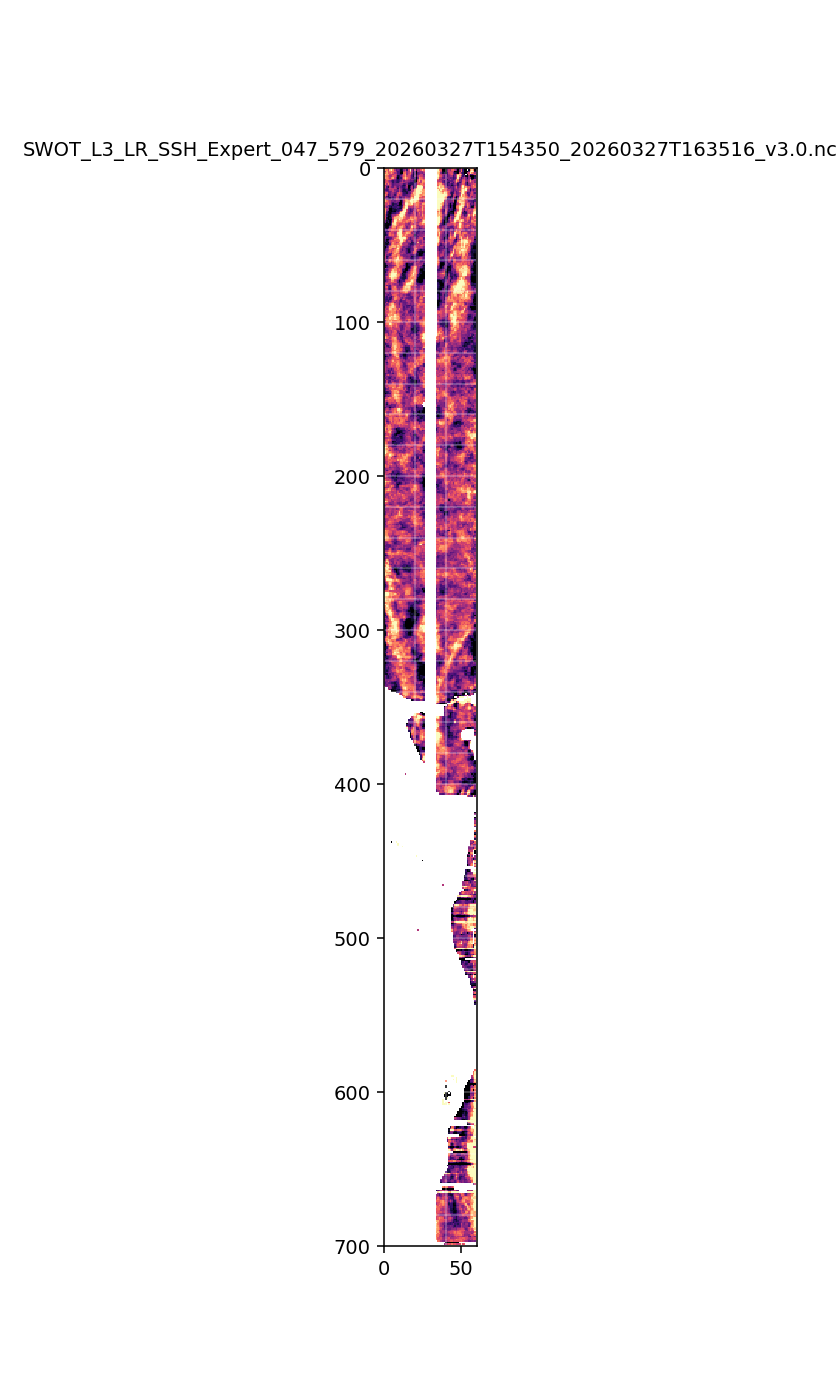

In [6]:
# Launch the tool

# %%
labeler = BlockLabelerFromProcessedNC(
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
    var_name=VAR_NAME,
    source_mask_var_name=SOURCE_MASK_VAR_NAME,
    output_mask_var_name=OUTPUT_MASK_VAR_NAME,
    orient_mode=ORIENT_MODE,
    block_h=BLOCK_H,
    block_w=BLOCK_W,
    majority_threshold=MAJORITY_THRESHOLD,
    source_mask_value=SOURCE_MASK_VALUE,
    fig_w_in=FIG_W_IN,
    fig_h_in=FIG_H_IN,
    fig_dpi=FIG_DPI,
)